# Krok 7. Efekt promocji (E3)
**Wynik z instrukcji:** o ile więcej sprzedaje się w dniu promocji niż w zwykłym dniu (np. ×1,8); na MVP z `CzyPromocja`. Dni promocyjne nie wchodzą do wyliczania Bazy. Poziom: `AsId` (duże SKU osobno). Dla wariantu `baseline_2`.

**Jak liczymy.**
1. **Baza towaru** = średnia sprzedaż na dzień czysty, **bez dni promocyjnych** i po usunięciu dnia tygodnia (mnożniki z kroku 4). To typowa sprzedaż towaru, gdy nic się nie dzieje.
2. **Mnożnik promocji towaru** = sprzedaż w dniach promocyjnych / (Baza × suma mnożników dnia tygodnia tych dni). Wynik 1,8 znaczy: w dniu promocji towar sprzedaje 1,8 razy więcej niż w zwykły dzień.
3. **Mnożnik asortymentu** = iloraz sum: suma sprzedaży w dniach promocyjnych wszystkich towarów asortymentu / suma tego, czego oczekiwalibyśmy bez promocji. Duże towary (co najmniej `MIN_DNI_PROMO` czystych dni promocyjnych) dostają własny mnożnik.

**Ograniczenia, które trzeba znać.** Flaga `CzyPromocja` jest wyliczona z cen, więc jest przybliżona. Leży na wierszach sprzedaży: promocja bez ani jednej sprzedaży jest niewidoczna, co zaniża mnożnik. Promocje bywają planowane na dni, które i tak sprzedają dobrze (np. weekend), więc część efektu może wynikać z wyboru terminu, a nie z samej promocji.

**Wynik zapisany do:** `dane/eda/wynik_07_promocje_asid.csv` i `dane/eda/wynik_07_promocje_sku.csv`. Wymaga kroku 4 i kolumny `CzyPromocja` w pliku.

In [13]:
# Ustawienia wspólne: moduł eda_wspolne.py leży obok tego notebooka
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_wspolne as ew

ew.wejdz_do_korzenia()      # przechodzi do katalogu głównego projektu (tam, gdzie jest plik z danymi)
ew.styl()
print("Katalog projektu:", os.getcwd(), "| EDA używa danych do", ew.KONIEC_EDA.date(), "(rok testowy", ew.ROK_TEST, "pomijamy)")

Katalog projektu: /Users/mixer/python/analiza_sprzedazy_w_sklepie | EDA używa danych do 2024-12-31 (rok testowy 2025 pomijamy)


## Dane i dostępność flagi promocji
#### Objaśnienie
**Po co.** Krok działa tylko z kolumną `CzyPromocja`. Jeśli jej nie ma w pliku, notebook zatrzymuje się z czytelnym komunikatem zamiast liczyć coś bez sensu.
**Co robi kod.** Zbiera sprzedaż do poziomu (towar, dzień): `q` to suma sztuk, `promo` to 1, jeśli którykolwiek wiersz tego dnia miał promocję. Dopisuje numer dnia, dzień tygodnia, mnożnik dnia tygodnia asortymentu (z kroku 4) i znacznik dnia czystego.
**Jak czytać wynik.** Wypisana liczba wierszy promocyjnych i towarów z promocją pokazuje skalę. Jeśli promocji jest mało (kilka dni na towar), oceny na poziomie towaru będą szumne i warto polegać na poziomie asortymentu.

In [14]:
assert ew.ma_kolumne("CzyPromocja"), "Brak kolumny CzyPromocja w pliku: ten krok wymaga flagi promocji (patrz opis na górze)"
fa = ew.wczytaj_sprzedaz(("CzyPromocja",))
kal = ew.kalendarz()
m4 = ew.wczytaj_wynik("wynik_04_mnoznik_dnia_tygodnia.csv", index_col=0)
m4.index = m4.index.astype(str)

sd = (fa.groupby(["SKU", "Data"], observed=True)
        .agg(q=(ew.MIARA, "sum"), promo=("CzyPromocja", "max"), AsId=("AsId", "first")).reset_index())
del fa
dzien = (sd["Data"] - kal.index[0]).dt.days.values
sd["dow"] = kal["DzienTyg"].values[dzien]
sd["czysty"] = kal["Czysty"].values[dzien]
sd["AsId"] = sd["AsId"].astype(str)
sd = sd[sd["dow"] < 6].copy()                                              # mnożnik jest tylko dla Pn-So
dzien = (sd["Data"] - kal.index[0]).dt.days.values
mdow = m4.loc[sd["AsId"].values, ew.DNI[:6]].values
sd["m"] = mdow[np.arange(len(sd)), sd["dow"].values]                       # mnożnik dnia tygodnia asortymentu
print(f"Wierszy (towar, dzień): {len(sd):,} | z promocją: {int((sd['promo'] == 1).sum()):,} | towarów z promocją: {sd.loc[sd['promo'] == 1, 'SKU'].nunique():,}".replace(",", " "))

Wierszy (towar  dzień): 1 054 056 | z promocją: 49 208 | towarów z promocją: 3 059


## Baza towaru i mnożnik promocji
#### Objaśnienie
**Po co.** Liczymy mnożnik promocji dla każdego towaru, a potem agregujemy do asortymentu.
**Co robi kod.**
- **Mianownik Bazy** to suma mnożników dnia tygodnia po wszystkich **dniach czystych** od pierwszej do ostatniej sprzedaży towaru (dni bez sprzedaży też są tu liczone jako zero, inaczej Baza byłaby zawyżona), pomniejszona o dni promocyjne. Sumę po dniach liczymy ze skumulowanych sum (jedno odejmowanie zamiast pętli).
- **Licznik Bazy** to sprzedaż w czystych dniach bez promocji.
- `promo_q` i `promo_m`: sprzedaż w czystych dniach promocyjnych i suma ich mnożników dnia tygodnia.
- Mnożnik towaru = `promo_q / (Baza × promo_m)`.
- Towar bierzemy do oceny, jeśli ma co najmniej 3 czyste dni promocyjne i Bazę większą od zera.
**Jak czytać wynik.** Rozkład mnożników towarów pokazuje, czy promocja zwykle podnosi sprzedaż i jak bardzo towary się różnią. Mediana poniżej 1 oznaczałaby, że promocje nie działają (albo flaga jest słaba).

In [15]:
cols = list(m4.index)                                                       # kolumny asortymentów
czysty_dni = kal["Czysty"].values
dow_dni = kal["DzienTyg"].values
M = m4[ew.DNI[:6]].values                                                   # asortymenty x 6
mdz = np.where((dow_dni < 6)[:, None], M.T[np.minimum(dow_dni, 5)], 0.0)   # dni x asortymenty
cum = np.cumsum(np.where(czysty_dni[:, None], mdz, 0.0), axis=0)           # skumulowana suma mnożników po dniach czystych
idx_as = {a: i for i, a in enumerate(cols)}

g = sd.groupby("SKU")
pierwszy = g["Data"].min(); ostatni = g["Data"].max()
f_i = ((pierwszy - kal.index[0]).dt.days).values; l_i = ((ostatni - kal.index[0]).dt.days).values
as_sku = g["AsId"].first()
j = np.array([idx_as[a] for a in as_sku.values])
okno_m = cum[l_i, j] - np.where(f_i > 0, cum[np.maximum(f_i - 1, 0), j], 0.0)       # suma mnożników dni czystych w życiu towaru

cl = sd[sd["czysty"]]
promo = cl[cl["promo"] == 1].groupby("SKU").agg(promo_q=("q", "sum"), promo_m=("m", "sum"), dni_promo=("q", "size"))
bezp = cl[cl["promo"] == 0].groupby("SKU").agg(bez_q=("q", "sum"))
t = pd.DataFrame({"AsId": as_sku, "okno_m": okno_m}).join(promo).join(bezp).dropna(subset=["promo_q"])
t["bez_q"] = t["bez_q"].fillna(0)
t["mianownik_bazy"] = t["okno_m"] - t["promo_m"]
t = t[(t["dni_promo"] >= 3) & (t["mianownik_bazy"] > 0)]
t["baza"] = t["bez_q"] / t["mianownik_bazy"]
t = t[t["baza"] > 0]
t["oczekiwane"] = t["baza"] * t["promo_m"]
t["mnoznik"] = t["promo_q"] / t["oczekiwane"]
print(f"Towarów oceniono: {len(t)} | mediana mnożnika: {t['mnoznik'].median():.2f} | kwartyle: "
      f"{t['mnoznik'].quantile(.25):.2f}-{t['mnoznik'].quantile(.75):.2f}")

Towarów oceniono: 2190 | mediana mnożnika: 4.03 | kwartyle: 2.53-7.39


## Mnożnik asortymentu i duże towary
#### Objaśnienie
**Po co.** Mnożnik asortymentu to wartość, której użyje `baseline_2`; duże towary (z dużą liczbą promocji) mają dość danych na własny mnożnik.
**Co robi kod.**
- Mnożnik asortymentu = suma sprzedaży promocyjnej / suma oczekiwanej sprzedaży (iloraz sum). Dzięki temu towary o większej sprzedaży mają większą wagę, a mikro-towary nie dominują wyniku.
- `MIN_DNI_PROMO` = 15 czystych dni promocyjnych: towary z taką liczbą dni dostają własny wiersz.
- Przedział `ci_dolny`/`ci_gorny`: 90 % przedział z 300 losowań ze zwracaniem **towarów** asortymentu. Pokazuje, jak bardzo wynik zależy od doboru towarów.
**Jak czytać wynik.** Wąski przedział i mnożnik wyraźnie powyżej 1 to wiarygodny efekt. Przedział obejmujący 1,0 oznacza, że w tym asortymencie nie wykazano efektu promocji.

      towary_z_promocja  dni_promo  mnoznik  ci_dolny  ci_gorny
AsId                                                           
86                   68       2386     2.04      1.85      2.34
115                  45       2006     1.75      1.56      2.12
70                   80       1738     2.25      1.91      3.08
223                  57       1723     3.21      2.84      3.76
95                   45       1641     2.01      1.80      2.34
98                   75       1599     2.20      1.99      2.53
217                  76       1571     2.52      2.26      2.88
90                   58       1481     2.09      1.92      2.45
112                  29       1445     2.17      1.81      2.99
97                   63       1380     2.63      2.29      3.33
326                 108       1379     3.17      2.88      3.59
161                  68       1196     3.14      2.84      3.49
84                   36       1092     2.60      2.33      2.91
99                   68       1024     2

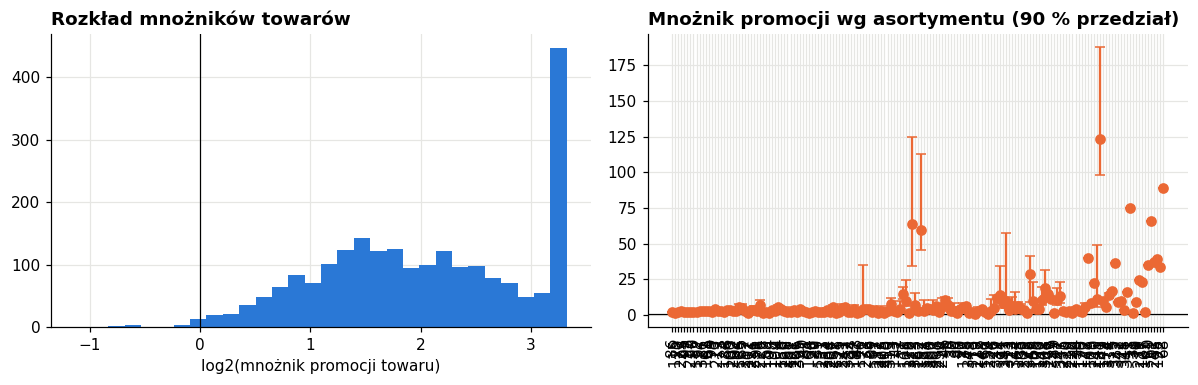

In [16]:
MIN_DNI_PROMO = 15
rng = np.random.default_rng(0)
wiersze = []
for a, d in t.groupby("AsId"):
    pq, ocz = d["promo_q"].values, d["oczekiwane"].values
    boot = [pq[i].sum() / ocz[i].sum() for i in (rng.integers(0, len(d), len(d)) for _ in range(300))]
    wiersze.append({"AsId": a, "towary_z_promocja": len(d), "dni_promo": int(d["dni_promo"].sum()),
                    "mnoznik": pq.sum() / ocz.sum(), "ci_dolny": np.quantile(boot, .05), "ci_gorny": np.quantile(boot, .95)})
asid = pd.DataFrame(wiersze).set_index("AsId").sort_values("dni_promo", ascending=False)
duze = t[t["dni_promo"] >= MIN_DNI_PROMO][["AsId", "dni_promo", "baza", "mnoznik"]].sort_values("dni_promo", ascending=False)
print(asid.round(2).to_string())
print(f"\nDuże towary (co najmniej {MIN_DNI_PROMO} czystych dni promocyjnych): {len(duze)}")
print(duze.head(10).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(np.log2(t["mnoznik"].clip(0.1, 10)), bins=30, color=ew.NIEB)
ax[0].axvline(0, color="black", lw=0.8); ax[0].set_xlabel("log2(mnożnik promocji towaru)"); ax[0].set_title("Rozkład mnożników towarów")
ax[1].errorbar(range(len(asid)), asid["mnoznik"], yerr=[asid["mnoznik"] - asid["ci_dolny"], asid["ci_gorny"] - asid["mnoznik"]],
               fmt="o", color=ew.POM, capsize=3)
ax[1].axhline(1, color="black", lw=0.8); ax[1].set_xticks(range(len(asid))); ax[1].set_xticklabels(asid.index, rotation=90)
ax[1].set_title("Mnożnik promocji wg asortymentu (90 % przedział)")
plt.tight_layout(); plt.show()

## Zapis
#### Objaśnienie
**Po co.** Zapisujemy mnożniki asortymentów oraz dużych towarów. `baseline_2` stosuje mnożnik towaru, jeśli istnieje, a w przeciwnym razie mnożnik asortymentu.
**Uwaga o liczeniu Bazy.** Skoro dni promocyjne nie wchodzą do Bazy, to kroki 4 i 5 już ich nie zawierają (wiersze z `CzyPromocja == 1` są tam wyłączone), a dzień czysty z promocją nie służy do żadnego mnożnika poza tym krokiem.

In [17]:
ew.zapisz_wynik(asid, "wynik_07_promocje_asid.csv")
ew.zapisz_wynik(duze.set_index("AsId", drop=False).rename_axis("indeks"), "wynik_07_promocje_sku.csv")

Zapisano: dane/eda/wynik_07_promocje_asid.csv (163 wierszy)
Zapisano: dane/eda/wynik_07_promocje_sku.csv (715 wierszy)


'dane/eda/wynik_07_promocje_sku.csv'